# quickstart

Generated with **Lispyn** — originally created by **Eduardo J. Barrios**.

Source: [Lispyn](https://github.com/edujbarrios/lispyn) (Apache-2.0).

In [1]:
import hy
hy.macros.require('lispyn.macros', None, target_module_name='quickstart', assignments=[['md', 'md']], prefix='')


[('md', 'md', <function lispyn.macros.md(*content)>)]

# Quickstart · from Lisp to an executed research notebook

A native PyTorch classifier on synthetic data. We reserve an unseen

test partition for a final, illustrative evaluation.

In [2]:
import hy
hy.macros.require('lispyn.macros', None, target_module_name='quickstart', assignments=[['experiment-params', 'experiment-params']], prefix='')


[('experiment_params',
  'experiment_params',
  <function lispyn.macros.experiment_params(*assignments)>)]

In [3]:
import hy
hy.macros.require('lispyn.macros', None, target_module_name='quickstart', assignments=[['experiment-params', 'experiment-params']], prefix='')
seed = 42
epochs = 10


In [4]:
import hy
hy.macros.require('lispyn.macros', None, target_module_name='quickstart', assignments=[['md', 'md']], prefix='')


[('md', 'md', <function lispyn.macros.md(*content)>)]

## 1. Prepare data and isolate the test set

Create two-dimensional toy samples; split them before training.

In [5]:
import hy
hy.macros.require('lispyn.macros', None, target_module_name='quickstart', assignments=[['train-val-test', 'train-val-test']], prefix='')
import torch
torch.manual_seed(seed)
features = torch.tensor([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0], [0.2, 0.3], [0.3, 0.9], [0.9, 0.3], [0.8, 0.9], [0.1, 0.2], [0.1, 0.8], [0.9, 0.2], [0.9, 0.8], [0.4, 0.1], [0.4, 0.9], [0.7, 0.1], [0.7, 0.9]])
labels = torch.tensor([0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1])
dataset = torch.utils.data.TensorDataset(features, labels)
from lispyn.data import split_dataset_three
[training, validation, held_out] = split_dataset_three(dataset, validation_fraction=0.25, test_fraction=0.25, seed=seed)
print('Samples:', len(training), 'train,', len(validation), 'validation,', len(held_out), 'held-out test')
hy.macros.require('lispyn.macros', None, target_module_name='quickstart', assignments=[['md', 'md']], prefix='')


Samples: 8 train, 4 validation, 4 held-out test


[('md', 'md', <function lispyn.macros.md(*content)>)]

## 2. Train a native PyTorch model

Lispyn handles the training loop and early stopping; model, optimizer

and tensors remain ordinary PyTorch objects.

In [6]:
import hy
hy.macros.require('lispyn.macros', None, target_module_name='quickstart', assignments=[['train-until', 'train-until']], prefix='')
model = torch.nn.Linear(2, 2)
from lispyn.workflow import train
run = train(model, training, patience=3, validation=validation, loss_fn=torch.nn.CrossEntropyLoss(), epochs=epochs, batch_size=4, lr=0.05, seed=seed, device='cpu')
print('Completed epochs:', len(run.history['train_loss']))
hy.macros.require('lispyn.macros', None, target_module_name='quickstart', assignments=[['md', 'md']], prefix='')


Completed epochs: 10


[('md', 'md', <function lispyn.macros.md(*content)>)]

## 3. Report and evaluate

Summarize recorded metrics, then evaluate the untouched test subset once.

This tiny synthetic dataset is a workflow demo, not research evidence.

In [7]:
import hy
hy.macros.require('lispyn.macros', None, target_module_name='quickstart', assignments=[['report-run', 'report-run'], ['narrate', 'narrate'], ['metric-table', 'metric-table']], prefix='')
from lispyn.training import evaluate_metrics
from lispyn.reporting import show_run_report
show_run_report(run, title='PyTorch baseline · recorded metrics')
held_out_loader = torch.utils.data.DataLoader(held_out, batch_size=4)
test_scores = evaluate_metrics(run.model, held_out_loader, loss_fn=torch.nn.CrossEntropyLoss(), metrics='accuracy', device='cpu')
from lispyn.narrative import show_narrative
show_narrative('Held-out test accuracy: **{accuracy:.1%}**', accuracy=test_scores['accuracy'])
from lispyn.narrative import show_metric_summary
show_metric_summary({'best_val_loss': min(run.history['val_loss']), 'test_loss': test_scores['loss'], 'test_accuracy': test_scores['accuracy']}, title='Recorded experiment scores', precision=4)
hy.macros.require('lispyn.macros', None, target_module_name='quickstart', assignments=[['md', 'md']], prefix='')


# PyTorch baseline · recorded metrics

**Epochs recorded:** 10
**Early stopping:** no

## Metrics

| Metric | Optimize | Best epoch | Best value | Final value |
| --- | --- | ---: | ---: | ---: |
| train_loss | min | 10 | 0.440579 | 0.440579 |
| val_loss | min | 10 | 0.429638 | 0.429638 |

_Best epochs are 1-based. This report contains only metric summaries, not raw dataset rows, predictions, or model weights._


Held-out test accuracy: **50.0%**

### Recorded experiment scores

| Metric | Value |
| --- | ---: |
| best_val_loss | 0.4296 |
| test_loss | 0.7664 |
| test_accuracy | 0.5 |


[('md', 'md', <function lispyn.macros.md(*content)>)]

## 4. Plot the real training history

Generated from the run.history actually recorded above, never fake curves.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


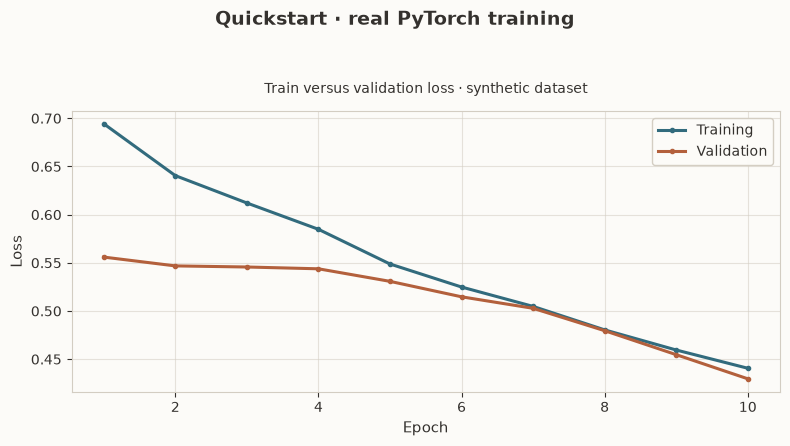

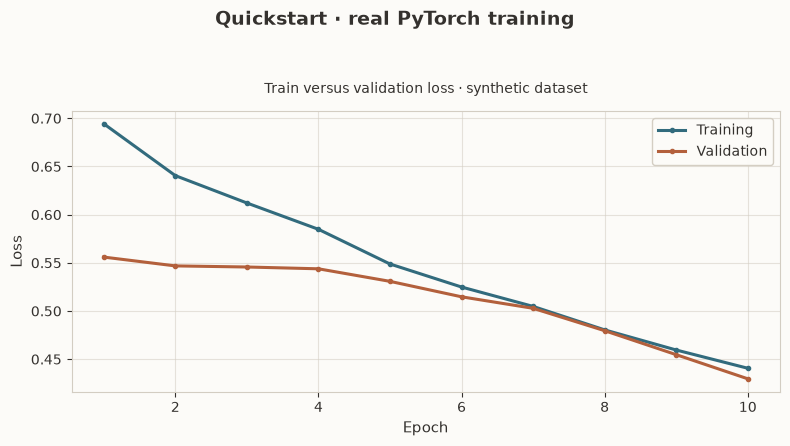

In [8]:
import hy
hy.macros.require('lispyn.macros', None, target_module_name='quickstart', assignments=[['curve', 'curve']], prefix='')
from lispyn.plots import plot_history
plot_history(run, metric='loss', theme='paper', title='Quickstart · real PyTorch training', subtitle='Train versus validation loss · synthetic dataset', figsize=[8, 4.5], save='../example_generated_notebooks/assets/quickstart_training_curves.png')
